In [31]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [32]:
df = pd.read_csv("WineQT.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [33]:
df.isnull().sum()    # There are no null values

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 107.3 KB


In [35]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [36]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

# INFERENCE - 
## volatile acidity, residual sugar, chlorides, free sulfur dioxde, total sulfer dioxide, sulphates have outliers based on the table above

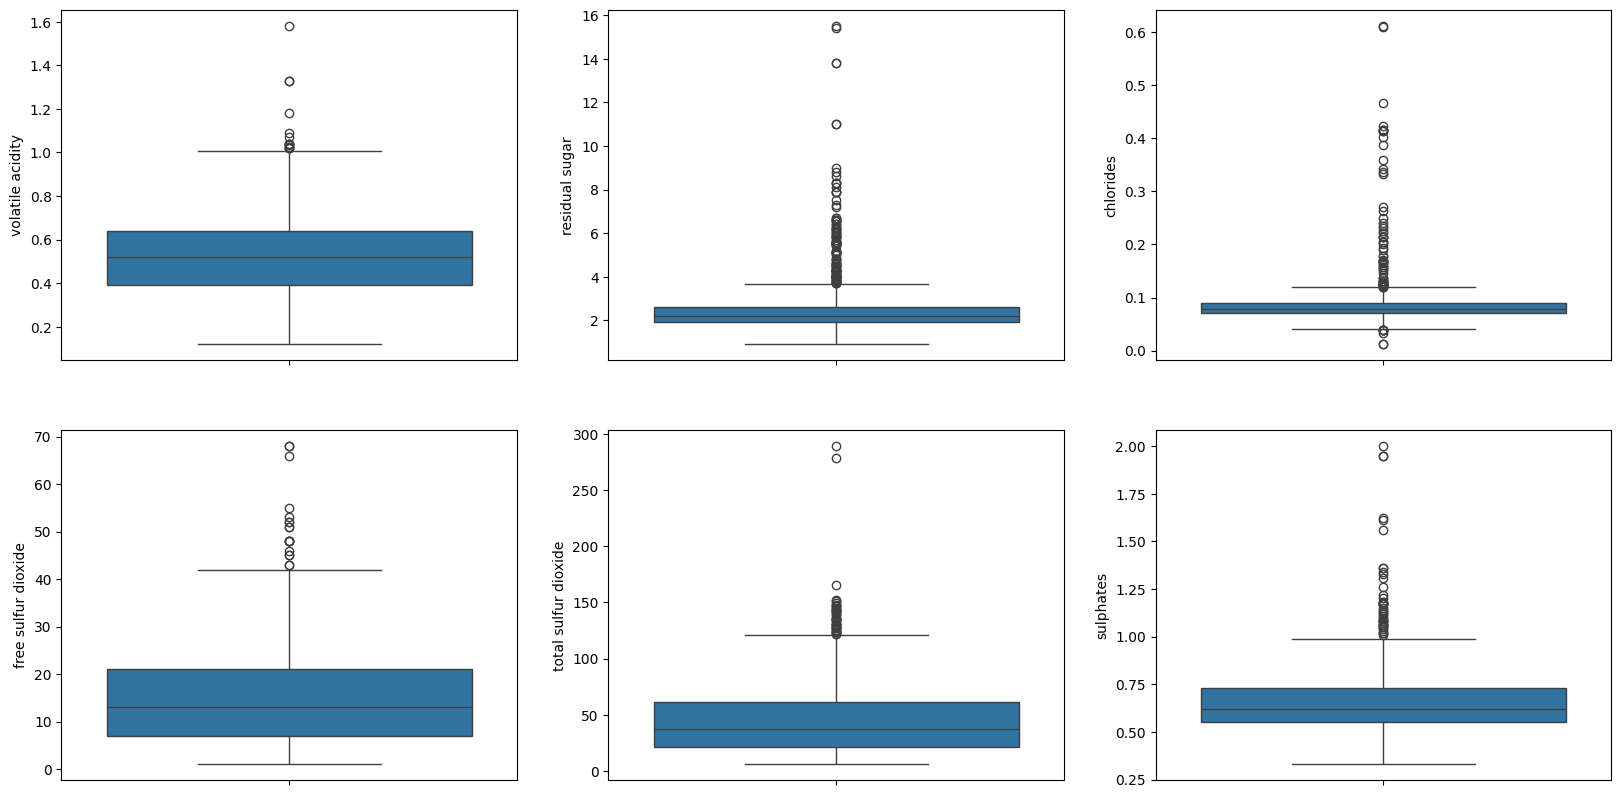

In [37]:
fig, axes = plt.subplots(2,3,figsize=(20,10))
axes = axes.flatten()
cols = ['volatile acidity', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'sulphates']
for i in range(len(axes)):
    sns.boxplot(data=df[cols[i]], ax=axes[i])
plt.show()

## From the above we can infer that - 
## Outliers - 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'sulphates'  

In [38]:
# Using quantiles & IQR to remove outliers

# residual sugar
Q1_rs = df['residual sugar'].quantile(0.25) 
Q3_rs = df['residual sugar'].quantile(0.75) 

IQR_rs = Q3_rs - Q1_rs

lower_rs = Q1_rs - 1.5 * IQR_rs
upper_rs = Q3_rs + 2.5 * IQR_rs

# Chlorides
Q1_ch = df['chlorides'].quantile(0.25)
Q3_ch = df['chlorides'].quantile(0.75)
IQR_ch = Q3_ch - Q1_ch

lower_ch = Q1_ch - 1.5 * IQR_ch
upper_ch = Q3_ch + 1.5 * IQR_ch

# Free Sulfur Dioxide
Q1_fsd = df['free sulfur dioxide'].quantile(0.25)
Q3_fsd = df['free sulfur dioxide'].quantile(0.75)
IQR_fsd = Q3_fsd - Q1_fsd

lower_fsd = Q1_fsd - 1.5 * IQR_fsd
upper_fsd = Q3_fsd + 2.5 * IQR_fsd

# Total Sulfur Dioxide
Q1_tsd = df['total sulfur dioxide'].quantile(0.25)
Q3_tsd = df['total sulfur dioxide'].quantile(0.75)
IQR_tsd = Q3_tsd - Q1_tsd

lower_tsd = Q1_tsd - 1.5 * IQR_tsd
upper_tsd = Q3_tsd + 1.8* IQR_tsd

# Sulphates
Q1_sul = df['sulphates'].quantile(0.25)
Q3_sul = df['sulphates'].quantile(0.75)
IQR_sul = Q3_sul - Q1_sul

lower_sul = Q1_sul - 1.5 * IQR_sul
upper_sul = Q3_sul + 1.65 * IQR_sul

df_filtered = df[
                    (df['residual sugar'] >= lower_rs) & (df['residual sugar'] <= upper_rs) &
                    (df['chlorides'] >= lower_ch) & (df['chlorides'] <= upper_ch) &
                    (df['free sulfur dioxide'] >= lower_fsd) & (df['free sulfur dioxide'] <= upper_fsd) &
                    (df['total sulfur dioxide'] >= lower_tsd) & (df['total sulfur dioxide'] <= upper_tsd) &
                    (df['sulphates'] >= lower_sul) & (df['sulphates'] <= upper_sul) 
]

print("Original rows:", len(df))
print("Filtered rows:", len(df_filtered))

Original rows: 1143
Filtered rows: 965


In [39]:
# Checking Filtered rows

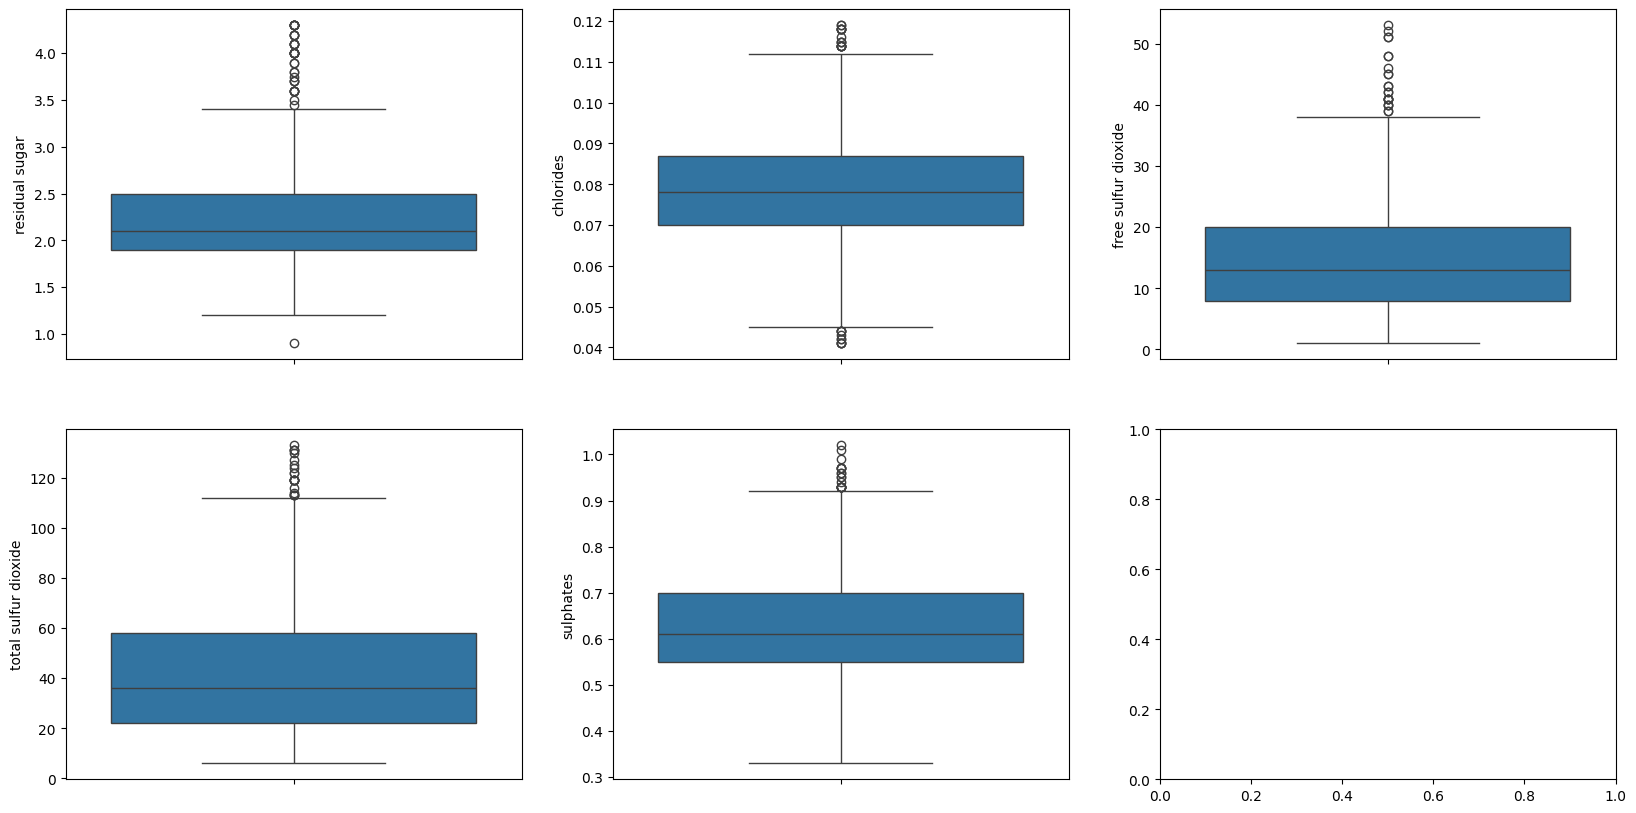

In [40]:
fig, axes = plt.subplots(2,3,figsize=(20,10))
axes = axes.flatten()
cols = ['residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'sulphates']
for i in range(len(cols)):
    sns.boxplot(data=df_filtered[cols[i]], ax=axes[i])
plt.show()

## Checking for Duplicates

In [41]:
df_filtered.duplicated().sum()   # there were 108 earlier

np.int64(108)

In [42]:
df_filtered = df_filtered.drop_duplicates()   # duplicated removed

In [43]:
df_filtered['quality'].value_counts().sort_index()

quality
3      3
4     25
5    364
6    354
7     99
8     12
Name: count, dtype: int64

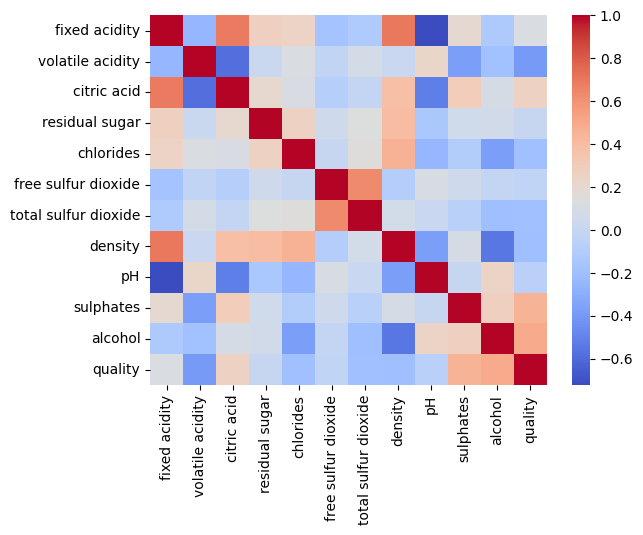

In [44]:
sns.heatmap(df_filtered.corr(), cmap = 'coolwarm')
plt.show()


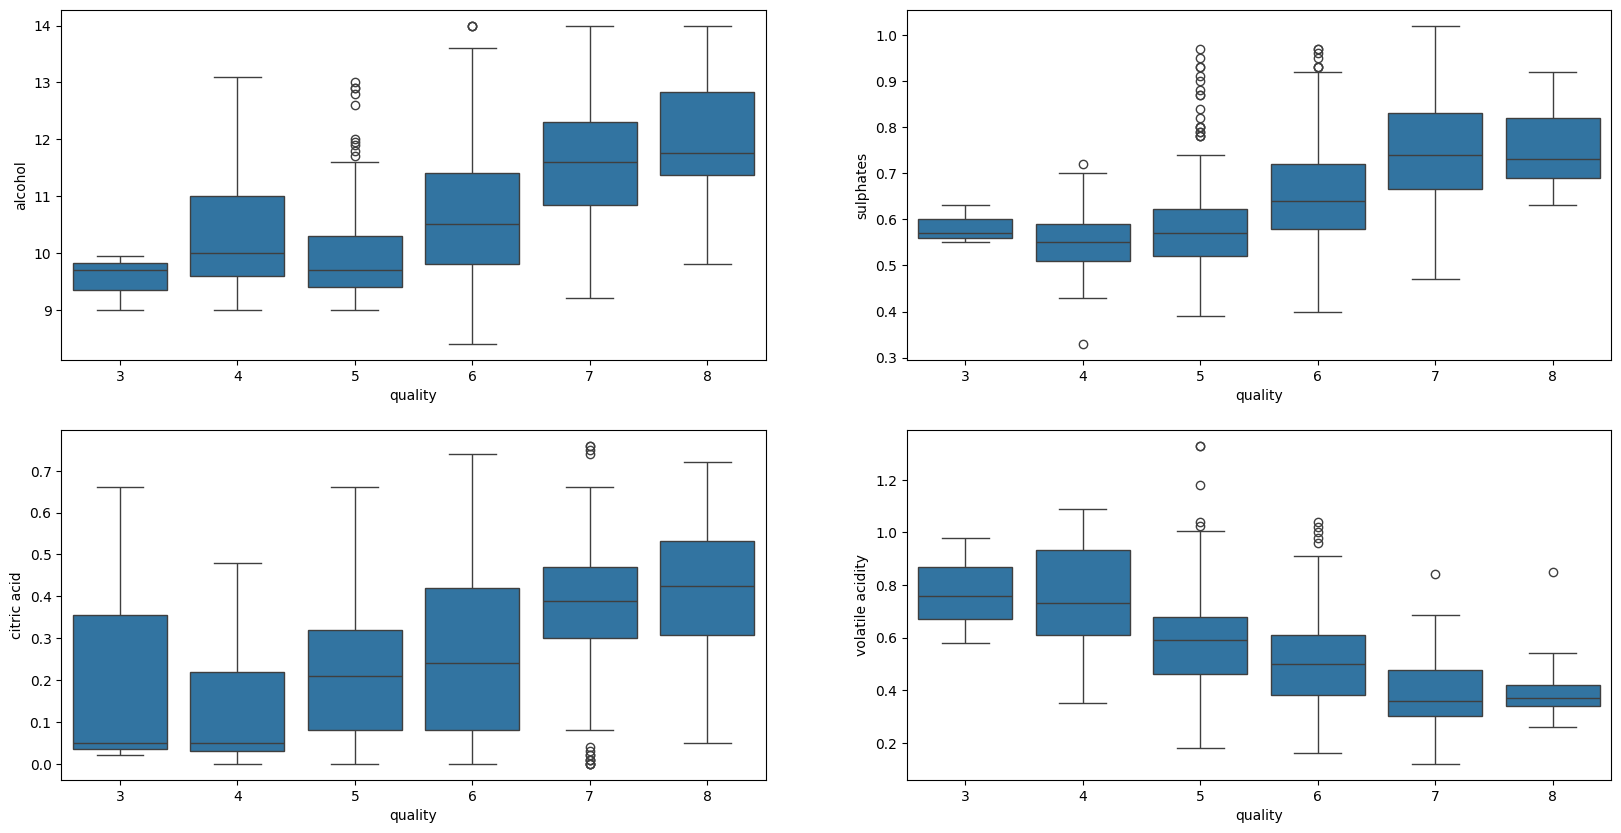

In [45]:
related_w_quality = ['alcohol', 'sulphates', 'citric acid', 'volatile acidity']
fig, axes = plt.subplots(2,2, figsize=(20,10))
axes = axes.flatten()
for i in range(len(axes)):
    sns.boxplot(x='quality', y=related_w_quality[i], data=df_filtered, ax = axes[i])
plt.show()

In [46]:
# alcohol and volatile acidity have a strong relationship
# alcohol increases gradually by its median
# median volatile acidity decreases as quality increases

# Training

In [47]:
# We need to convert the values of quality into binary numbers - 0 /1  

In [48]:
df_filtered.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


In [49]:
df_filtered['quality'] = (df_filtered['quality'] >= 6).astype(int)
df_filtered['quality'].value_counts()

quality
1    465
0    392
Name: count, dtype: int64

In [50]:
X = df_filtered.drop('quality', axis = 1)
y = df_filtered['quality']

In [53]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
# fitting model

In [54]:
from sklearn.ensemble import RandomForestClassifier
classify = RandomForestClassifier()

In [56]:
classify.fit(X_train, y_train)

RandomForestClassifier()

In [57]:
y_predict = classify.predict(X_test)

In [60]:
from sklearn.metrics import classification_report

In [61]:
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       0.70      0.63      0.67        79
           1       0.71      0.77      0.74        93

    accuracy                           0.71       172
   macro avg       0.71      0.70      0.70       172
weighted avg       0.71      0.71      0.71       172



## ***Defining a Hyperparameter Grid for Grid Search
## A dictionary grid_param is defined to specify the hyperparameters and their values for the grid search n_estimators: Number of trees in the forest.
## Criterion: Function to measure the quality of a split (gini or entropy).
## max_depth: Maximum depth of the trees (ranging from 0 to 4 in this example).

In [63]:
classify.estimators_


[DecisionTreeClassifier(max_features='sqrt', random_state=1282860031),
 DecisionTreeClassifier(max_features='sqrt', random_state=1417557230),
 DecisionTreeClassifier(max_features='sqrt', random_state=906139626),
 DecisionTreeClassifier(max_features='sqrt', random_state=637451304),
 DecisionTreeClassifier(max_features='sqrt', random_state=650031910),
 DecisionTreeClassifier(max_features='sqrt', random_state=2048496343),
 DecisionTreeClassifier(max_features='sqrt', random_state=1901792139),
 DecisionTreeClassifier(max_features='sqrt', random_state=163451276),
 DecisionTreeClassifier(max_features='sqrt', random_state=1726816663),
 DecisionTreeClassifier(max_features='sqrt', random_state=424872981),
 DecisionTreeClassifier(max_features='sqrt', random_state=1520796904),
 DecisionTreeClassifier(max_features='sqrt', random_state=489812947),
 DecisionTreeClassifier(max_features='sqrt', random_state=660472659),
 DecisionTreeClassifier(max_features='sqrt', random_state=1368986434),
 DecisionTree

In [78]:
grid_param = {
    'n_estimators' : [50,100,150,200],
    'criterion' : ['gini', 'entropy'],
    'max_depth' : [None,3,5,7,10],
    'min_samples_split' : [2,5,10],
    'min_samples_leaf' : [1,2,4]
}

In [79]:
from sklearn.model_selection import GridSearchCV
grid_search_classify = GridSearchCV(estimator=classify, param_grid=grid_param, n_jobs=6, cv=8, verbose=1)
grid_search_classify.fit(X_train, y_train)

Fitting 8 folds for each of 360 candidates, totalling 2880 fits


GridSearchCV(cv=8, estimator=RandomForestClassifier(), n_jobs=6,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [None, 3, 5, 7, 10],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 150, 200]},
             verbose=1)

In [80]:
grid_search_classify.best_params_

{'criterion': 'gini',
 'max_depth': 10,
 'min_samples_leaf': 4,
 'min_samples_split': 2,
 'n_estimators': 100}

In [81]:
classify_new = RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=10, min_samples_leaf=4, min_samples_split=2)
classify_new.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, min_samples_leaf=4)

In [82]:
y_new_predict = classify_new.predict(X_test)

In [83]:
print(classification_report(y_test, y_new_predict))

              precision    recall  f1-score   support

           0       0.69      0.63      0.66        79
           1       0.71      0.76      0.74        93

    accuracy                           0.70       172
   macro avg       0.70      0.70      0.70       172
weighted avg       0.70      0.70      0.70       172

